# Week 5 – Mid-Review: Data Audit and Initial Statistical Findings
## Ames Housing Dataset Analysis

**Course:** 24ADI204 – Data Science & Visualization  
**Team:** Team 8  
**Milestone:** Mid-Review – The Data Audit  

### Objectives
1. Audit the cleaned dataset produced in Week 3.
2. Verify dimensions, data types, missing values and duplicate records.
3. Calculate measures of central tendency and dispersion.
4. Calculate skewness and kurtosis for numerical features.
5. Examine mean-versus-median differences and relationships with `SalePrice`.
6. Conduct and interpret clearly stated hypothesis tests.
7. Save the cleaned mid-review dataset, statistical tables and figures for reproducibility.

### Data lineage
The notebook loads `Week 3/AmesHousing_Uncleaned_Cleaned.csv` directly. It does not repeat the cleaning process or silently replace the Week 3 dataset. The resulting Week 5 CSV is a reproducible copy of this cleaned input.

## 1. Import libraries and load the Week 3 cleaned dataset

Run from the repository root or from inside the `Week 5` folder. The loader preserves the structural-absence label `None` and treats genuinely blank CSV fields as missing.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)

DATA_FILENAME = "AmesHousing_Uncleaned_Cleaned.csv"

def find_repo_root():
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        if (candidate / "Week 3" / DATA_FILENAME).is_file():
            return candidate
    raise FileNotFoundError(
        f"Could not locate Week 3/{DATA_FILENAME}. "
        "Run this notebook from the repository root or the Week 5 folder."
    )

ROOT = find_repo_root()
DATA_PATH = ROOT / "Week 3" / DATA_FILENAME
OUTPUT_DIR = ROOT / "Week 5" / "week5_outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# The text value 'None' is kept as a valid category; blank strings become NaN.
df = pd.read_csv(DATA_PATH, keep_default_na=False, na_values=[""])

NUMERIC_CANDIDATES = [
    "Order", "PID", "MS SubClass", "Lot Frontage", "Lot Area", "Overall Qual",
    "Overall Cond", "Year Built", "Year Remod/Add", "Mas Vnr Area", "BsmtFin SF 1",
    "BsmtFin SF 2", "Bsmt Unf SF", "Total Bsmt SF", "1st Flr SF", "2nd Flr SF",
    "Low Qual Fin SF", "Gr Liv Area", "Bsmt Full Bath", "Bsmt Half Bath", "Full Bath",
    "Half Bath", "Bedroom AbvGr", "Kitchen AbvGr", "TotRms AbvGrd", "Fireplaces",
    "Garage Yr Blt", "Garage Cars", "Garage Area", "Wood Deck SF", "Open Porch SF",
    "Enclosed Porch", "3Ssn Porch", "Screen Porch", "Pool Area", "Misc Val",
    "Mo Sold", "Yr Sold", "SalePrice"
]
for column in NUMERIC_CANDIDATES:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")

required_columns = ["SalePrice", "Overall Qual", "Gr Liv Area"]
missing_required = [c for c in required_columns if c not in df.columns]
if missing_required:
    raise KeyError(f"Required columns missing from cleaned dataset: {missing_required}")

print(f"Loaded: {DATA_PATH.relative_to(ROOT)}")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]:,} columns")
print(f"Missing cells: {int(df.isna().sum().sum()):,}")
print(f"Duplicate rows: {int(df.duplicated().sum()):,}")
display(df.head())

Loaded: Week 3/AmesHousing_Uncleaned_Cleaned.csv
Shape: 2,930 rows × 82 columns
Missing cells: 0
Duplicate rows: 0


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,50.0,RL,68.0,31770,Pave,None,IR1,Lvl,...,0,None,None,None,0,5,2010,WD,Normal,215000
1,2,526350040,20.0,RH,80.0,11622,Pave,None,Reg,Lvl,...,0,None,MnPrv,None,0,6,2010,WD,Normal,105000
2,3,526351010,20.0,RL,81.0,14267,Pave,None,IR1,Lvl,...,0,None,None,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20.0,RL,93.0,11160,Pave,None,Reg,Lvl,...,0,None,None,None,0,4,2010,WD,Normal,244000
4,5,527105010,60.0,RL,74.0,13830,Pave,None,IR1,Lvl,...,0,None,MnPrv,None,0,3,2010,WD,Normal,189900


## 2. Mid-review data audit

This audit reports the health of the Week 3 cleaned dataset. A value of zero for missing cells and duplicate rows is the expected result from the Week 3 cleaning output. The notebook reports deviations rather than hiding them.

In [2]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(exclude=np.number).columns.tolist()

audit_summary = pd.DataFrame({
    "Audit Metric": [
        "Total rows", "Total columns", "Numerical columns", "Categorical columns",
        "Duplicate rows", "Missing cells", "SalePrice missing values"
    ],
    "Result": [
        len(df), df.shape[1], len(numeric_columns), len(categorical_columns),
        int(df.duplicated().sum()), int(df.isna().sum().sum()),
        int(df["SalePrice"].isna().sum())
    ]
})

data_quality = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Non-Missing": df.notna().sum(),
    "Missing Values": df.isna().sum(),
    "Missing Percent": (df.isna().mean() * 100).round(2),
    "Unique Values": df.nunique(dropna=True)
}).sort_values("Missing Values", ascending=False)

display(audit_summary)
display(data_quality.head(20))

audit_summary.to_csv(OUTPUT_DIR / "week5_data_audit_summary.csv", index=False)
data_quality.to_csv(OUTPUT_DIR / "week5_data_quality_by_column.csv")

if audit_summary.loc[audit_summary["Audit Metric"] == "Missing cells", "Result"].iat[0] == 0:
    print("PASS: No missing cells detected in the cleaned dataset.")
else:
    print("REVIEW REQUIRED: Missing cells remain; inspect week5_data_quality_by_column.csv.")

if int(df.duplicated().sum()) == 0:
    print("PASS: No exact duplicate rows detected.")
else:
    print("REVIEW REQUIRED: Duplicate rows remain; inspect before analysis.")

,Audit Metric,Result
0,Total rows,2930
1,Total columns,82
2,Numerical columns,39
3,Categorical columns,43
4,Duplicate rows,0
5,Missing cells,0
6,SalePrice missing values,0


,Data Type,Non-Missing,Missing Values,Missing Percent,Unique Values
Order,int64,2930,0,0.0,2930
PID,int64,2930,0,0.0,2930
MS SubClass,float64,2930,0,0.0,16
MS Zoning,str,2930,0,0.0,7
Lot Frontage,float64,2930,0,0.0,126
Lot Area,int64,2930,0,0.0,1960
Street,str,2930,0,0.0,2
Alley,str,2930,0,0.0,3
Lot Shape,str,2930,0,0.0,4
Land Contour,str,2930,0,0.0,4


PASS: No missing cells detected in the cleaned dataset.
PASS: No exact duplicate rows detected.


## 3. Descriptive statistics: central tendency and dispersion

The statistics include mean, median, mode, standard deviation, variance, minimum, maximum, quartiles and interquartile range. Identifier columns (`Order` and `PID`) are excluded from feature interpretation.

In [3]:
analysis_columns = [c for c in numeric_columns if c not in {"Order", "PID"}]

statistics_rows = []
for column in analysis_columns:
    values = df[column].dropna()
    if values.empty:
        continue
    modes = values.mode()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    statistics_rows.append({
        "Feature": column,
        "Count": int(values.count()),
        "Mean": values.mean(),
        "Median": values.median(),
        "Mode (first if tied)": modes.iloc[0] if not modes.empty else np.nan,
        "Std Dev": values.std(),
        "Variance": values.var(),
        "Minimum": values.min(),
        "Q1": q1,
        "Q3": q3,
        "Maximum": values.max(),
        "IQR": q3 - q1,
        "Skewness": values.skew(),
        "Kurtosis (Fisher)": values.kurt()
    })

descriptive_stats = pd.DataFrame(statistics_rows).set_index("Feature").round(4)
display(descriptive_stats)
descriptive_stats.to_csv(OUTPUT_DIR / "week5_descriptive_statistics.csv")

,Count,Mean,Median,Mode (first if tied),Std Dev,Variance,Minimum,Q1,Q3,Maximum,IQR,Skewness,Kurtosis (Fisher)
Feature,,,,,,,,,,,,,
MS SubClass,2930,57.2935,50.0,20.0,41.8217,1.749057e+03,20.0,20.00,70.00,190.0,50.00,1.3876,1.5463
Lot Frontage,2930,68.9041,68.0,68.0,20.9739,4.399058e+02,21.0,60.00,78.00,313.0,18.00,1.7450,15.2070
Lot Area,2930,10147.9218,9436.5,9600.0,7880.0178,6.209468e+07,1300.0,7440.25,11555.25,215245.0,4115.00,12.8209,265.0237
Overall Qual,2930,6.0949,6.0,5.0,1.4110,1.991000e+00,1.0,5.00,7.00,10.0,2.00,0.1906,0.0524
Overall Cond,2930,5.5631,5.0,5.0,1.1115,1.235500e+00,1.0,5.00,6.00,9.0,1.00,0.5744,1.4914
Year Built,2930,1971.3563,1973.0,2005.0,30.2454,9.147818e+02,1872.0,1954.00,2001.00,2010.0,47.00,-0.6045,-0.5017
Year Remod/Add,2930,1984.2666,1993.0,1950.0,20.8603,4.351515e+02,1950.0,1965.00,2004.00,2010.0,39.00,-0.4519,-1.3415
Mas Vnr Area,2930,101.0969,0.0,0.0,178.6345,3.191030e+04,0.0,0.00,162.75,1600.0,162.75,2.6193,9.3687
BsmtFin SF 1,2930,442.4785,370.0,0.0,455.5865,2.075590e+05,0.0,0.00,734.00,5644.0,734.00,1.4164,6.8585


## 4. Mean, median and distribution-shape analysis

Mean and median are compared as descriptive measures. Skewness is calculated directly and should be used as the main numerical measure of asymmetry. Kurtosis below is **Fisher excess kurtosis**, where a normal distribution has a value of approximately zero.

In [4]:
shape_table = descriptive_stats[[
    "Mean", "Median", "Skewness", "Kurtosis (Fisher)"
]].copy()
shape_table["Mean - Median"] = shape_table["Mean"] - shape_table["Median"]
shape_table = shape_table[["Mean", "Median", "Mean - Median", "Skewness", "Kurtosis (Fisher)"]]
display(shape_table.sort_values("Skewness", ascending=False))
shape_table.to_csv(OUTPUT_DIR / "week5_distribution_shape.csv")

skewness_table = descriptive_stats[["Skewness", "Kurtosis (Fisher)"]].sort_values(
    "Skewness", ascending=False
)
display(skewness_table.head(15))
skewness_table.to_csv(OUTPUT_DIR / "week5_skewness_kurtosis.csv")

,Mean,Median,Mean - Median,Skewness,Kurtosis (Fisher)
Feature,,,,,
Misc Val,50.6352,0.0,50.6352,21.9998,566.2033
Pool Area,2.2433,0.0,2.2433,16.9391,299.7749
Lot Area,10147.9218,9436.5,711.4218,12.8209,265.0237
Low Qual Fin SF,4.6768,0.0,4.6768,12.1182,175.6069
3Ssn Porch,2.5925,0.0,2.5925,11.4038,149.9887
Kitchen AbvGr,1.0444,1.0,0.0444,4.3138,19.8697
BsmtFin SF 2,49.7055,0.0,49.7055,4.1408,18.7893
Enclosed Porch,23.0116,0.0,23.0116,4.0144,28.4872
Screen Porch,16.0020,0.0,16.0020,3.9575,17.8592


,Skewness,Kurtosis (Fisher)
Feature,,
Misc Val,21.9998,566.2033
Pool Area,16.9391,299.7749
Lot Area,12.8209,265.0237
Low Qual Fin SF,12.1182,175.6069
3Ssn Porch,11.4038,149.9887
Kitchen AbvGr,4.3138,19.8697
BsmtFin SF 2,4.1408,18.7893
Enclosed Porch,4.0144,28.4872
Screen Porch,3.9575,17.8592


## 5. Correlation analysis with SalePrice

Pearson correlation measures the strength and direction of a linear relationship between two numerical variables. Correlation does not establish causation. Identifier fields are excluded.

,Pearson Correlation with SalePrice
Overall Qual,0.799262
Gr Liv Area,0.706780
Garage Cars,0.647562
Garage Area,0.640138
Total Bsmt SF,0.632529
1st Flr SF,0.621676
Year Built,0.558426
Full Bath,0.545604
Year Remod/Add,0.532974
Mas Vnr Area,0.502196


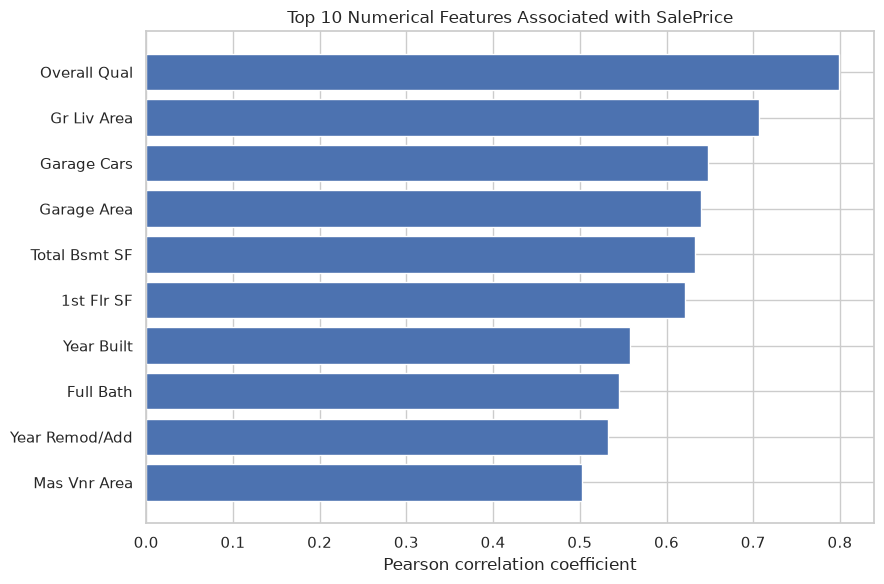

In [5]:
correlation_data = df[analysis_columns].copy()
correlation_matrix = correlation_data.corr(numeric_only=True)
correlation_matrix.to_csv(OUTPUT_DIR / "week5_correlation_matrix.csv")

saleprice_correlations = correlation_matrix["SalePrice"].drop("SalePrice", errors="ignore")
saleprice_correlations = saleprice_correlations.dropna().reindex(
    saleprice_correlations.dropna().abs().sort_values(ascending=False).index
)
correlation_table = saleprice_correlations.rename(
    "Pearson Correlation with SalePrice"
).to_frame()
display(correlation_table.head(15))
correlation_table.to_csv(OUTPUT_DIR / "week5_saleprice_correlations.csv")

fig, ax = plt.subplots(figsize=(9, 6))
top_corr = correlation_table.head(10).sort_values(
    "Pearson Correlation with SalePrice"
)
ax.barh(top_corr.index.astype(str), top_corr["Pearson Correlation with SalePrice"])
ax.set_xlabel("Pearson correlation coefficient")
ax.set_title("Top 10 Numerical Features Associated with SalePrice")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "top_saleprice_correlations.png", dpi=160, bbox_inches="tight")
display(fig)
plt.close(fig)

## 6. Hypothesis testing

The tests below provide explicit examples for the weekly statistical lab log. Each test states its null and alternative hypotheses and uses a 5% significance level (`alpha = 0.05`). A small p-value is evidence against the null hypothesis; it does not prove causation.

### Test A – Association between Overall Quality and SalePrice
- **H₀:** There is no population association between Overall Quality and SalePrice.
- **H₁:** There is a population association between Overall Quality and SalePrice.

Pearson correlation tests linear association. Spearman correlation is also reported because Overall Quality is an ordered rating.

In [6]:
ALPHA = 0.05
hypothesis_results = []

def record_test(name, method, null_hypothesis, alternative_hypothesis, statistic, p_value, n):
    decision = "Reject H0" if p_value < ALPHA else "Fail to reject H0"
    hypothesis_results.append({
        "Test": name,
        "Method": method,
        "Null hypothesis": null_hypothesis,
        "Alternative hypothesis": alternative_hypothesis,
        "Statistic": float(statistic),
        "P-value": float(p_value),
        "N": int(n),
        "Alpha": ALPHA,
        "Decision": decision
    })

quality_price = df[["Overall Qual", "SalePrice"]].dropna()
pearson_result = stats.pearsonr(quality_price["Overall Qual"], quality_price["SalePrice"])
record_test(
    "Overall Qual vs SalePrice", "Pearson correlation",
    "Population Pearson correlation = 0",
    "Population Pearson correlation != 0",
    pearson_result.statistic, pearson_result.pvalue, len(quality_price)
)

spearman_result = stats.spearmanr(quality_price["Overall Qual"], quality_price["SalePrice"])
record_test(
    "Overall Qual vs SalePrice", "Spearman rank correlation",
    "Population Spearman correlation = 0",
    "Population Spearman correlation != 0",
    spearman_result.statistic, spearman_result.pvalue, len(quality_price)
)

living_price = df[["Gr Liv Area", "SalePrice"]].dropna()
living_result = stats.pearsonr(living_price["Gr Liv Area"], living_price["SalePrice"])
record_test(
    "Gr Liv Area vs SalePrice", "Pearson correlation",
    "Population Pearson correlation = 0",
    "Population Pearson correlation != 0",
    living_result.statistic, living_result.pvalue, len(living_price)
)

tests_table = pd.DataFrame(hypothesis_results)
display(tests_table)
tests_table.to_csv(OUTPUT_DIR / "week5_hypothesis_tests.csv", index=False)

for row in hypothesis_results:
    print(
        f"{row['Test']} ({row['Method']}): {row['Decision']} at alpha={ALPHA:.2f}; "
        f"statistic={row['Statistic']:.4f}, p-value={row['P-value']:.4g}."
    )

,Test,Method,Null hypothesis,Alternative hypothesis,Statistic,P-value,N,Alpha,Decision
0,Overall Qual vs SalePrice,Pearson correlation,Population Pearson correlation = 0,Population Pearson correlation != 0,0.799262,0.0,2930,0.05,Reject H0
1,Overall Qual vs SalePrice,Spearman rank correlation,Population Spearman correlation = 0,Population Spearman correlation != 0,0.808800,0.0,2930,0.05,Reject H0
2,Gr Liv Area vs SalePrice,Pearson correlation,Population Pearson correlation = 0,Population Pearson correlation != 0,0.706780,0.0,2930,0.05,Reject H0


Overall Qual vs SalePrice (Pearson correlation): Reject H0 at alpha=0.05; statistic=0.7993, p-value=0.
Overall Qual vs SalePrice (Spearman rank correlation): Reject H0 at alpha=0.05; statistic=0.8088, p-value=0.
Gr Liv Area vs SalePrice (Pearson correlation): Reject H0 at alpha=0.05; statistic=0.7068, p-value=0.


## 7. Group comparison: SalePrice by Overall Quality

This comparison examines whether the SalePrice distributions differ between properties rated 8–10 and properties rated below 8. The group boundary is an analyst-defined descriptive split, not a rulebook threshold.

- **H₀:** The SalePrice distributions are the same in the two groups.
- **H₁:** The SalePrice distributions differ between the two groups.

The Mann–Whitney U test is used because SalePrice is positively skewed. It tests for a difference in rank distributions; it should not be described as a direct test of equality of means.

,Group,Properties,Mean SalePrice,Median SalePrice,Std Dev SalePrice
0,Overall Qual >= 8,488,303665.018443,286000.0,91428.844077
1,Overall Qual < 8,2442,156242.394349,148800.0,48669.820444


,Test,Method,H0,H1,U statistic,P-value,Alpha,Decision
0,SalePrice distribution by Overall Qual group,Mann–Whitney U (two-sided),The two SalePrice distributions are the same,The two SalePrice distributions differ,1130407.5,1.670075e-215,0.05,Reject H0


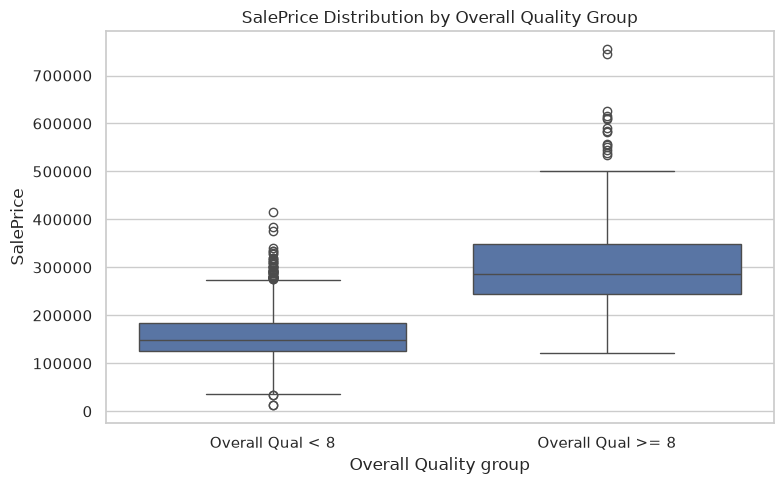

In [7]:
quality_groups = df[["Overall Qual", "SalePrice"]].dropna().copy()
high_quality = quality_groups.loc[quality_groups["Overall Qual"] >= 8, "SalePrice"]
other_quality = quality_groups.loc[quality_groups["Overall Qual"] < 8, "SalePrice"]

if len(high_quality) == 0 or len(other_quality) == 0:
    raise ValueError("Both Overall Qual comparison groups must contain observations.")

mann_whitney = stats.mannwhitneyu(
    high_quality, other_quality, alternative="two-sided", method="auto"
)
quality_group_summary = pd.DataFrame({
    "Group": ["Overall Qual >= 8", "Overall Qual < 8"],
    "Properties": [len(high_quality), len(other_quality)],
    "Mean SalePrice": [high_quality.mean(), other_quality.mean()],
    "Median SalePrice": [high_quality.median(), other_quality.median()],
    "Std Dev SalePrice": [high_quality.std(), other_quality.std()]
})
display(quality_group_summary)

group_test = pd.DataFrame([{
    "Test": "SalePrice distribution by Overall Qual group",
    "Method": "Mann–Whitney U (two-sided)",
    "H0": "The two SalePrice distributions are the same",
    "H1": "The two SalePrice distributions differ",
    "U statistic": float(mann_whitney.statistic),
    "P-value": float(mann_whitney.pvalue),
    "Alpha": ALPHA,
    "Decision": "Reject H0" if mann_whitney.pvalue < ALPHA else "Fail to reject H0"
}])
display(group_test)
quality_group_summary.to_csv(OUTPUT_DIR / "week5_quality_group_summary.csv", index=False)
group_test.to_csv(OUTPUT_DIR / "week5_quality_group_hypothesis_test.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=quality_groups.assign(
    Quality_Group=np.where(quality_groups["Overall Qual"] >= 8, "Overall Qual >= 8", "Overall Qual < 8")
), x="Quality_Group", y="SalePrice", ax=ax)
ax.set_title("SalePrice Distribution by Overall Quality Group")
ax.set_xlabel("Overall Quality group")
ax.set_ylabel("SalePrice")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "saleprice_by_quality_group.png", dpi=160, bbox_inches="tight")
display(fig)
plt.close(fig)

## 8. Distribution plots for mid-review evidence

The plots below support the statistical tables: the target distribution, its boxplot and the relationship between living area and sale price.

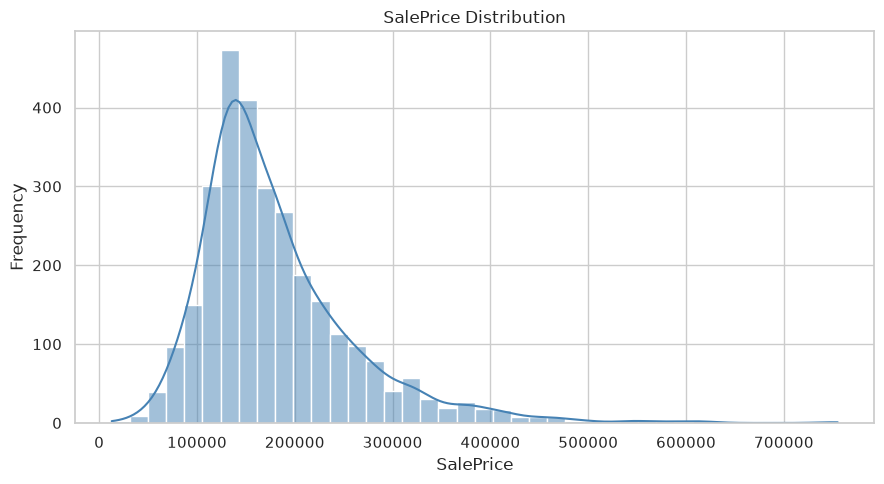

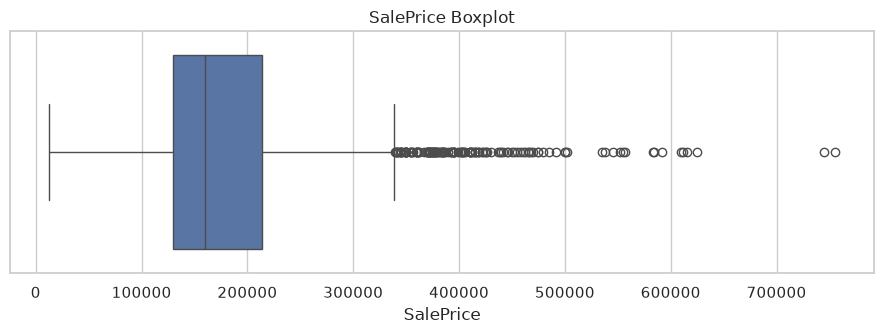

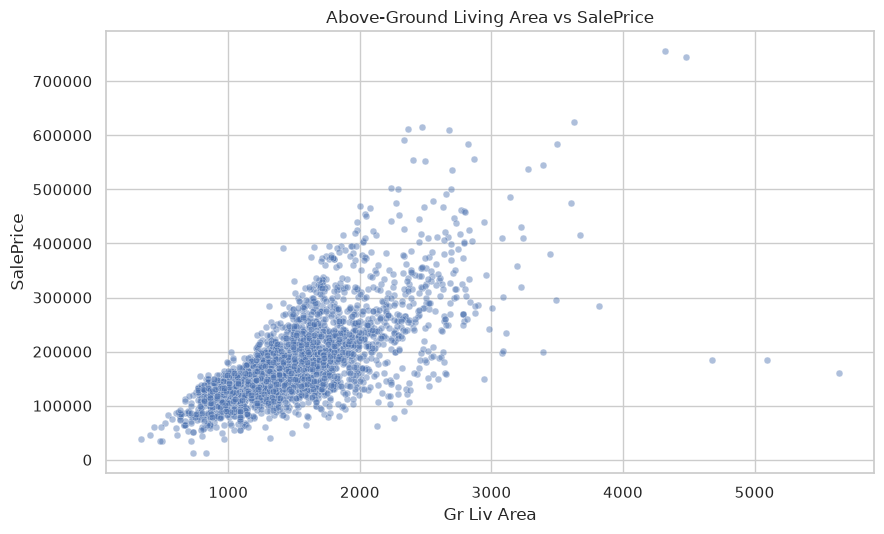

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df["SalePrice"].dropna(), bins=40, kde=True, color="steelblue", ax=ax)
ax.set_title("SalePrice Distribution")
ax.set_xlabel("SalePrice")
ax.set_ylabel("Frequency")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "saleprice_distribution.png", dpi=160, bbox_inches="tight")
display(fig)
plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 3.5))
sns.boxplot(x=df["SalePrice"].dropna(), ax=ax)
ax.set_title("SalePrice Boxplot")
ax.set_xlabel("SalePrice")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "saleprice_boxplot.png", dpi=160, bbox_inches="tight")
display(fig)
plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(data=df, x="Gr Liv Area", y="SalePrice", alpha=0.45, s=24, ax=ax)
ax.set_title("Above-Ground Living Area vs SalePrice")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "living_area_vs_saleprice.png", dpi=160, bbox_inches="tight")
display(fig)
plt.close(fig)

## 9. Key statistical findings

The findings are generated from the current dataset and saved as a text file. Read these together with the tables and hypothesis-test output. Do not report a p-value as proof of causality.

In [9]:
findings = []
price_mean = df["SalePrice"].mean()
price_median = df["SalePrice"].median()
price_skew = df["SalePrice"].skew()
price_kurtosis = df["SalePrice"].kurt()

findings.append(
    f"SalePrice mean = {price_mean:,.2f}; median = {price_median:,.2f}; "
    f"standard deviation = {df['SalePrice'].std():,.2f}; skewness = {price_skew:.3f}; "
    f"Fisher excess kurtosis = {price_kurtosis:.3f}."
)

if not saleprice_correlations.empty:
    strongest_feature = saleprice_correlations.index[0]
    strongest_r = saleprice_correlations.iloc[0]
    findings.append(
        f"The strongest absolute Pearson correlation with SalePrice among the analysed "
        f"numeric features is {strongest_feature} (r = {strongest_r:.3f})."
    )

findings.append(
    f"The cleaned dataset contains {len(df):,} rows and {df.shape[1]:,} columns, "
    f"with {int(df.isna().sum().sum()):,} missing cells and {int(df.duplicated().sum()):,} duplicate rows."
)

for row in hypothesis_results:
    findings.append(
        f"{row['Method']} for {row['Test']}: {row['Decision']} at alpha={ALPHA:.2f} "
        f"(statistic={row['Statistic']:.4f}, p={row['P-value']:.4g})."
    )

findings.append(
    f"Mann–Whitney U comparison of the two Overall Qual groups: "
    f"{group_test.loc[0, 'Decision']} at alpha={ALPHA:.2f} "
    f"(U={mann_whitney.statistic:.2f}, p={mann_whitney.pvalue:.4g}). "
    "This is a rank-distribution comparison, not a test of equality of means."
)

for i, finding in enumerate(findings, start=1):
    print(f"{i}. {finding}")

(OUTPUT_DIR / "week5_key_statistical_findings.txt").write_text(
    "WEEK 5 – KEY STATISTICAL FINDINGS\n\n" + "\n".join(
        f"{i}. {finding}" for i, finding in enumerate(findings, start=1)
    ), encoding="utf-8"
)

1. SalePrice mean = 180,796.06; median = 160,000.00; standard deviation = 79,886.69; skewness = 1.744; Fisher excess kurtosis = 5.119.
2. The strongest absolute Pearson correlation with SalePrice among the analysed numeric features is Overall Qual (r = 0.799).
3. The cleaned dataset contains 2,930 rows and 82 columns, with 0 missing cells and 0 duplicate rows.
4. Pearson correlation for Overall Qual vs SalePrice: Reject H0 at alpha=0.05 (statistic=0.7993, p=0).
5. Spearman rank correlation for Overall Qual vs SalePrice: Reject H0 at alpha=0.05 (statistic=0.8088, p=0).
6. Pearson correlation for Gr Liv Area vs SalePrice: Reject H0 at alpha=0.05 (statistic=0.7068, p=0).
7. Mann–Whitney U comparison of the two Overall Qual groups: Reject H0 at alpha=0.05 (U=1130407.50, p=1.67e-215). This is a rank-distribution comparison, not a test of equality of means.


898

## 10. Export the mid-review dataset and outputs

The Week 5 cleaned CSV is a copy of the Week 3 cleaned input. No additional imputation or outlier deletion is performed in this notebook. Exported values and tables are regenerated whenever the notebook is run.

In [10]:
week5_cleaned_copy = ROOT / "Week 5" / "Cleaned_AmesHousing_Week5.csv"
df.to_csv(week5_cleaned_copy, index=False)

print(f"Week 5 cleaned dataset copy saved: {week5_cleaned_copy.relative_to(ROOT)}")
print(f"Output tables and findings saved in: {OUTPUT_DIR.relative_to(ROOT)}")
print(f"Figures saved in: {FIGURE_DIR.relative_to(ROOT)}")

Week 5 cleaned dataset copy saved: Week 5/Cleaned_AmesHousing_Week5.csv
Output tables and findings saved in: Week 5/week5_outputs
Figures saved in: Week 5/week5_outputs/figures


## 11. Conclusion and mid-review checklist

Week 5 presents the data audit and the initial statistical findings required for the mid-review. It reports the health of the cleaned dataset, describes central tendency and dispersion, calculates skewness and kurtosis, examines numerical relationships and demonstrates hypothesis testing with stated hypotheses and significance level.

### Submission checklist
- [ ] Confirm the audit reports no unexpected missing values or duplicate rows.
- [ ] Review descriptive statistics, skewness and kurtosis tables.
- [ ] Review correlation results without making causal claims.
- [ ] Record the hypotheses, significance level, test statistic, p-value and decision in the lab log.
- [ ] Keep the generated Week 5 CSV, tables, findings text and figures with the submission.

**Interpretation note:** Statistical significance does not measure practical importance. Report the correlation coefficient, group summaries and p-value together.